# Consistency

Within-label duration SD for three types of labels: manual annotations, automatic label predictions, and labels that have been shuffled within each chunk. The visualization uses metrics precomputed using the `label_shuffle` column (see `src/metrics/README.md`).

In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from viz.utils import set_mpl_style
set_mpl_style()
from pipeline.collect_metrics import load_metrics

from viz.rows import row_height_ratios, annotate_row_groups, clean_density_yaxis
from fig2_settings import SECTIONS, build_row_specs, SERIES_COLORS, LABEL_TYPE_NAMES

In [2]:
_, _, label_metrics = load_metrics()
label_metrics = label_metrics.reset_index()

In [3]:
row_specs = build_row_specs(SECTIONS)
ROW_HEIGHT_RATIOS = row_height_ratios(row_specs, header_ratio=0.12)

In [4]:
def plot_consistency_ax(ax, datasets, rhythm_type, label_metrics, colors=SERIES_COLORS, names=LABEL_TYPE_NAMES):
    manual = label_metrics.query("dataset_id in @datasets and rhythm_type == @rhythm_type and label_type == 'annot'")['dur_std']
    pred = label_metrics.query("dataset_id in @datasets and rhythm_type == @rhythm_type and label_type == 'pred'")['dur_std']
    null_vals = label_metrics.query("dataset_id in @datasets and rhythm_type == @rhythm_type and label_type == 'shuffle'")['dur_std']
    manual, pred, null_vals = (s[s > 1e-5] for s in (manual, pred, null_vals))  # a handful of ~0ms singleton labels break the log x-axis

    shared_kws = dict(log_scale=True, legend=False, fill=True, ax=ax, linewidth=1)
    sns.kdeplot(x=manual, color=colors['annot'], alpha=.5, **shared_kws)
    sns.kdeplot(x=null_vals, color=colors['shuffle'], alpha=.3, linestyle="--", **shared_kws)
    if len(pred):
        sns.kdeplot(x=pred, color=colors['pred'], alpha=.15, **shared_kws)

    clean_density_yaxis(ax)
    return [
        plt.Rectangle((0, 0), 1, 1, color=colors['annot'], alpha=0.5, label=names['annot']),
        plt.Rectangle((0, 0), 1, 1, color=colors['pred'], alpha=0.5, label=names['pred']),
        plt.Rectangle((0, 0), 1, 1, color=colors['shuffle'], linestyle="--", alpha=0.3, label=names['shuffle']),
    ]

In [5]:
def plot_consistency_column(
    axes, row_specs, label_metrics, show_row_labels=True, legend=True,
    legend_loc='upper left', legend_bbox_to_anchor=(1.02, 1), legend_ax='first',
):
    handles, first_data_ax, last_data_ax = None, None, None
    for ax, (kind, row_label, spec) in zip(axes, row_specs):
        if kind == 'header':
            ax.axis('off')
            continue
        datasets, rhythm_type = spec
        row_handles = plot_consistency_ax(ax, datasets, rhythm_type, label_metrics)
        handles = handles or row_handles
        first_data_ax = first_data_ax or ax
        last_data_ax = ax
        if show_row_labels:
            ax.set_ylabel(row_label, rotation=0, ha='right', va='center', fontsize=7, labelpad=6)
    if legend and first_data_ax is not None:
        anchor_ax = first_data_ax if legend_ax == 'first' else last_data_ax
        anchor_ax.legend(
            handles=handles, loc=legend_loc, bbox_to_anchor=legend_bbox_to_anchor, fontsize=7,
            frameon=True, title_fontsize=7,
        )
    return axes

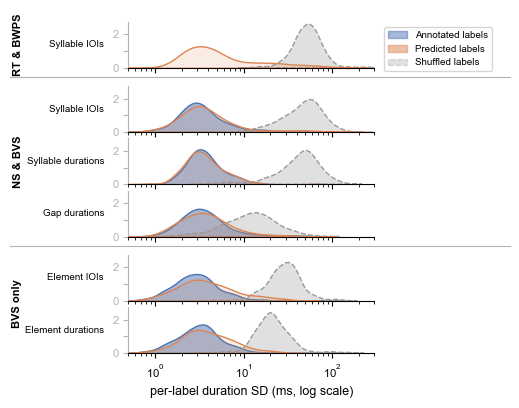

In [6]:
fig, axes = plt.subplots(
    len(row_specs), 1, figsize=(5, 0.5 * sum(ROW_HEIGHT_RATIOS) + 1),
    gridspec_kw=dict(height_ratios=ROW_HEIGHT_RATIOS), sharex=True, sharey=True
)
plot_consistency_column(axes, row_specs, label_metrics)

axes[-1].set_xlim(0.5, 300)
axes[-1].set_xlabel('per-label duration SD (ms, log scale)')
sns.despine()
fig.tight_layout(h_pad=0)
annotate_row_groups(fig, axes, row_specs)